In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [2]:

data = load_breast_cancer()


df = pd.DataFrame(data.data, columns=data.feature_names)


df["target"] = data.target


df["diagnosis"] = df["target"].map({
    0: "malignant",
    1: "benign"
})


print(df.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst perimeter  worst area  worst smoothness  \
0          

In [3]:

print("Dataset Shape:", df.shape)


print("\nFirst Five Rows:")
print(df.head())


print("\nColumn Names:")
print(df.columns)


print("\nDataset Information:")
df.info()


print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (569, 32)

First Five Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst perimeter  

In [4]:

print("Missing Values:")
print(df.isnull().sum())


print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
diagnosis                  0
dtype: int64

Total Missing Values: 0


In [5]:

df_clean = df.copy()

feature_cols = data.feature_names.tolist()


df_clean[feature_cols] = df_clean[feature_cols].fillna(
    df_clean[feature_cols].median()
)


print("Missing values after preprocessing:")
print(df_clean.isnull().sum().sum())

Missing values after preprocessing:
0


In [6]:

print("Before Encoding:")
print(df_clean["diagnosis"].head())

encoder = LabelEncoder()


df_clean["diagnosis_encoded"] = encoder.fit_transform(
    df_clean["diagnosis"]
)


print("\nAfter Encoding:")
print(df_clean[["diagnosis", "diagnosis_encoded"]].head())

Before Encoding:
0    malignant
1    malignant
2    malignant
3    malignant
4    malignant
Name: diagnosis, dtype: object

After Encoding:
   diagnosis  diagnosis_encoded
0  malignant                  1
1  malignant                  1
2  malignant                  1
3  malignant                  1
4  malignant                  1


In [7]:

X = df_clean[feature_cols].copy()

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=feature_cols
)

print(X_scaled_df.head())

print("\nMean of first feature:", X_scaled_df.iloc[:, 0].mean())
print("Standard deviation:", X_scaled_df.iloc[:, 0].std())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0     1.097064     -2.073335        1.269934   0.984375         1.568466   
1     1.829821     -0.353632        1.685955   1.908708        -0.826962   
2     1.579888      0.456187        1.566503   1.558884         0.942210   
3    -0.768909      0.253732       -0.592687  -0.764464         3.283553   
4     1.750297     -1.151816        1.776573   1.826229         0.280372   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0          3.283515        2.652874             2.532475       2.217515   
1         -0.487072       -0.023846             0.548144       0.001392   
2          1.052926        1.363478             2.037231       0.939685   
3          3.402909        1.915897             1.451707       2.867383   
4          0.539340        1.371011             1.428493      -0.009560   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

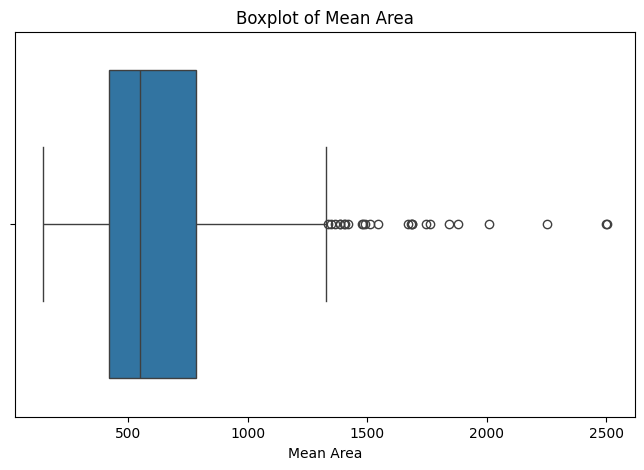

In [8]:

feature = "mean area"


plt.figure(figsize=(8, 5))

sns.boxplot(x=df_clean[feature])

plt.title("Boxplot of Mean Area")
plt.xlabel("Mean Area")

plt.show()

In [9]:

feature = "mean area"

Q1 = df_clean[feature].quantile(0.25)
Q3 = df_clean[feature].quantile(0.75)


IQR = Q3 - Q1


lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df_clean[feature] < lower_bound) |
    (df_clean[feature] > upper_bound)
)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Potential Outliers:", outlier_mask.sum())

df_no_outliers = df_clean.loc[~outlier_mask].copy()

print("\nOriginal Dataset Shape:", df_clean.shape)
print("Dataset Shape After Outlier Removal:", df_no_outliers.shape)

Lower Bound: -123.30000000000001
Upper Bound: 1326.3000000000002
Number of Potential Outliers: 25

Original Dataset Shape: (569, 33)
Dataset Shape After Outlier Removal: (544, 33)


In [10]:
print("========== PREPROCESSING SUMMARY ==========")

print("\nOriginal Dataset Shape:")
print(df.shape)

print("\nCleaned Dataset Shape:")
print(df_clean.shape)

print("\nDataset Shape After Outlier Removal:")
print(df_no_outliers.shape)

print("\nMissing Values Before Cleaning:")
print(df.isnull().sum().sum())

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum().sum())

print("\nTarget Distribution:")
print(df_clean["diagnosis"].value_counts())

print("\nFirst Five Rows of Cleaned Dataset:")
print(df_clean.head())

========== PREPROCESSING SUMMARY ==========

Original Dataset Shape:
(569, 32)

Cleaned Dataset Shape:
(569, 33)

Dataset Shape After Outlier Removal:
(544, 33)

Missing Values Before Cleaning:
0

Missing Values After Cleaning:
0

Target Distribution:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64

First Five Rows of Cleaned Dataset:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.086

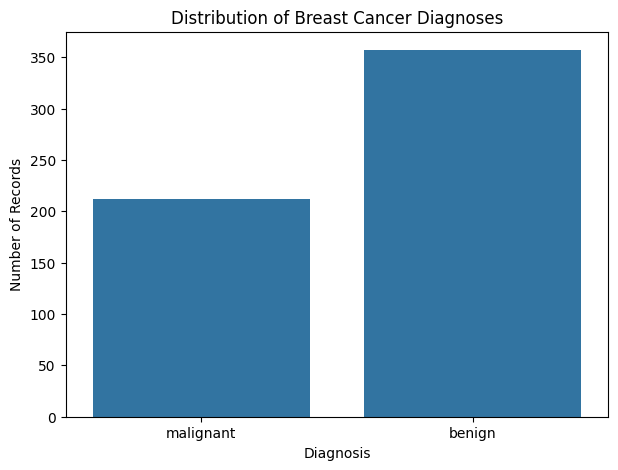

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="diagnosis")

plt.title("Distribution of Breast Cancer Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")

plt.show()